# Hands-On Data Lab Implementation
**Objectives:** (1) set up and verify a data science environment (Python, Jupyter, required libraries);
(2) complete practical exercises in **data manipulation**, **visualization** and **basic analysis**.

Dataset: a retail sales dataset (`data/sales.csv`, `data/products.csv`) generated by `src/generate_data.py`.
It contains deliberate problems (missing values and duplicate rows) so that cleaning can be practised.

## Part 1 - Environment setup and verification

In [1]:
import sys, platform
import numpy, pandas, matplotlib, seaborn, scipy, sklearn
import IPython

print("Python      :", sys.version.split()[0])
print("Platform    :", platform.system(), platform.release())
print("IPython     :", IPython.__version__)
for lib in (numpy, pandas, matplotlib, seaborn, scipy, sklearn):
    print(f"{lib.__name__:<12}:", lib.__version__)

Python      : 3.12.3
Platform    : Linux 6.18.44-fc-v230
IPython     : 9.18.1
numpy       : 2.4.4
pandas      : 3.0.2
matplotlib  : 3.10.8
seaborn     : 0.13.2
scipy       : 1.17.1
sklearn     : 1.8.0


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.2f}".format)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs"; OUT.mkdir(exist_ok=True)
print("Environment ready. Data folder:", ROOT / "data")

Environment ready. Data folder: /home/claude/data-lab/data


## Part 2 - Data manipulation

### Exercise 2.1 - Load and inspect the data

In [3]:
sales = pd.read_csv(ROOT / "data" / "sales.csv")
products = pd.read_csv(ROOT / "data" / "products.csv")
print("sales    :", sales.shape)
print("products :", products.shape)
sales.head()

sales    : (2025, 8)
products : (20, 4)


,order_id,order_date,customer_id,product_id,quantity,region,payment_method,discount_pct
0,10001,2025-12-11,C0253,P004,3,East,Card,0.00
1,10002,2025-08-17,C0348,P008,5,West,Card,0.00
2,10003,2025-12-01,C0110,P018,3,East,UPI,5.00
3,10004,2025-11-24,C0352,P013,2,South,Cash,15.00
4,10005,2025-07-31,C0026,P009,4,East,UPI,10.00


In [4]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 2025 entries, 0 to 2024
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        2025 non-null   int64  
 1   order_date      2025 non-null   str    
 2   customer_id     2025 non-null   str    
 3   product_id      2025 non-null   str    
 4   quantity        2025 non-null   int64  
 5   region          1984 non-null   str    
 6   payment_method  2025 non-null   str    
 7   discount_pct    1995 non-null   float64
dtypes: float64(1), int64(2), str(5)
memory usage: 126.7 KB


In [5]:
print("Missing values per column:")
print(sales.isna().sum()[lambda s: s > 0])
print("\nDuplicate rows:", sales.duplicated().sum())

Missing values per column:
region          41
discount_pct    30
dtype: int64

Duplicate rows: 25


### Exercise 2.2 - Clean the data

In [6]:
clean = sales.drop_duplicates().copy()                       # 1. remove duplicates
clean["order_date"] = pd.to_datetime(clean["order_date"])    # 2. fix data types
clean["region"] = clean["region"].fillna("Unknown")          # 3. categorical NaN -> label
clean["discount_pct"] = clean["discount_pct"].fillna(0)      # 4. missing discount -> no discount
print("Rows after cleaning:", len(clean))
print("Remaining missing values:", int(clean.isna().sum().sum()))
print(clean.dtypes)

Rows after cleaning: 2000
Remaining missing values: 0
order_id                   int64
order_date        datetime64[us]
customer_id                  str
product_id                   str
quantity                   int64
region                       str
payment_method               str
discount_pct             float64
dtype: object


### Exercise 2.3 - Merge tables and engineer features

In [7]:
df = clean.merge(products, on="product_id", how="left")
df["gross"]    = df["quantity"] * df["unit_price"]
df["revenue"]  = df["gross"] * (1 - df["discount_pct"] / 100)
df["month"]    = df["order_date"].dt.to_period("M").dt.to_timestamp()
df["weekday"]  = df["order_date"].dt.day_name()
df["is_weekend"] = df["order_date"].dt.dayofweek >= 5
df[["order_id", "product_name", "category", "quantity", "unit_price", "discount_pct", "revenue", "weekday"]].head()

,order_id,product_name,category,quantity,unit_price,discount_pct,revenue,weekday
0,10001,Headphones,Electronics,3,120,0.00,360.00,Thursday
1,10002,Mouse,Electronics,5,25,0.00,125.00,Sunday
2,10003,Dumbbells,Lifestyle,3,60,5.00,171.00,Monday
3,10004,Notebook,Stationery,2,4,15.00,6.80,Monday
4,10005,Desk,Furniture,4,250,10.00,900.00,Thursday


### Exercise 2.4 - Filter, sort and select

In [8]:
# Orders above 3,000 in the North region, highest revenue first
big_north = (df.query("region == 'North' and revenue > 3000")
               .sort_values("revenue", ascending=False)
               [["order_id", "product_name", "quantity", "revenue"]])
print("Large North orders:", len(big_north))
big_north.head()

Large North orders: 16


,order_id,product_name,quantity,revenue
222,10223,Laptop,5,"4,500.00"
730,10731,Laptop,5,"4,500.00"
1410,11411,Laptop,5,"4,500.00"
1731,11732,Laptop,5,"4,500.00"
1121,11122,Laptop,5,"4,050.00"


### Exercise 2.5 - Group, aggregate and pivot

In [9]:
by_category = (df.groupby("category")
                 .agg(orders=("order_id", "count"), units=("quantity", "sum"),
                      revenue=("revenue", "sum"), avg_order_value=("revenue", "mean"))
                 .sort_values("revenue", ascending=False))
by_category

,orders,units,revenue,avg_order_value
category,,,,
Electronics,1115,3326,"1,055,714.50",946.83
Furniture,331,981,"135,109.75",408.19
Lifestyle,333,974,"52,474.00",157.58
Stationery,221,649,"5,071.40",22.95


In [10]:
pivot = df.pivot_table(index="region", columns="category", values="revenue", aggfunc="sum", margins=True)
pivot

category,Electronics,Furniture,Lifestyle,Stationery,All
region,,,,,
East,"314,295.00","33,851.00","15,109.25","1,518.40","364,773.65"
North,"240,056.50","39,431.50","17,570.25","1,321.60","298,379.85"
South,"269,374.75","31,891.75","10,325.00",703.60,"312,295.10"
Unknown,"18,855.25","1,957.50",191.00,67.80,"21,071.55"
West,"213,133.00","27,978.00","9,278.50","1,460.00","251,849.50"
All,"1,055,714.50","135,109.75","52,474.00","5,071.40","1,248,369.65"


In [11]:
top_products = (df.groupby("product_name")["revenue"].sum()
                  .sort_values(ascending=False).head(5))
top_products

product_name
Laptop       350,775.00
Phone        273,357.50
Tablet       151,920.00
Monitor      121,875.00
Smartwatch    75,064.00
Name: revenue, dtype: float64

### Exercise 2.6 - NumPy basics and customer-level aggregation

In [12]:
rev = df["revenue"].to_numpy()
print("Mean  :", rev.mean().round(2))
print("Median:", np.median(rev).round(2))
print("Std   :", rev.std(ddof=1).round(2))
print("90th percentile:", np.percentile(rev, 90).round(2))

customers = (df.groupby("customer_id")
               .agg(orders=("order_id", "count"), total_spend=("revenue", "sum"))
               .sort_values("total_spend", ascending=False))
customers.head()

Mean  : 624.18
Median: 240.0
Std   : 862.28
90th percentile: 1714.5


,orders,total_spend
customer_id,,
C0174,6,"12,125.00"
C0062,4,"11,615.00"
C0094,4,"11,190.00"
C0039,6,"11,129.00"
C0320,7,"10,536.50"


## Part 3 - Data visualization

### Exercise 3.1 - Monthly revenue trend (line chart)

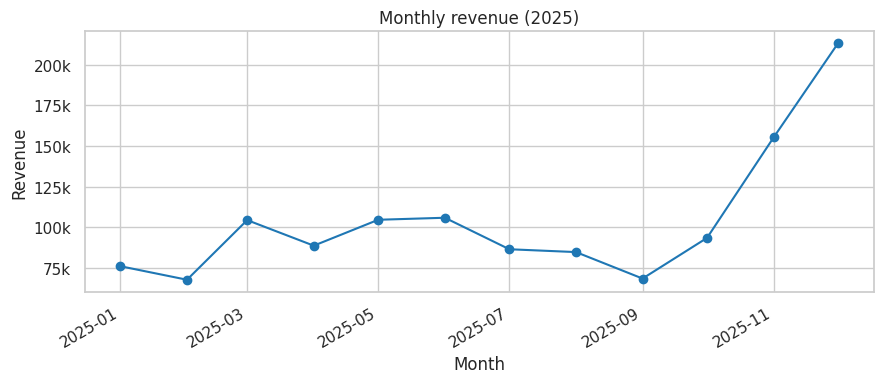

In [13]:
monthly = df.groupby("month")["revenue"].sum()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly.values, marker="o", color="#1f77b4")
ax.set(title="Monthly revenue (2025)", xlabel="Month", ylabel="Revenue")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(OUT / "01_monthly_revenue.png", dpi=150); plt.show()

### Exercise 3.2 - Revenue by category (bar chart)

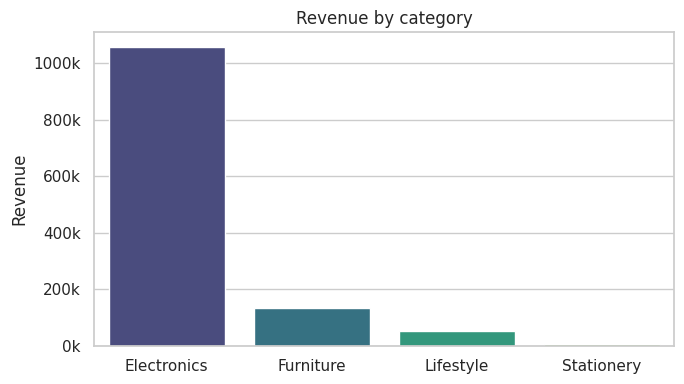

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=by_category.index, y=by_category["revenue"], hue=by_category.index, palette="viridis", legend=False, ax=ax)
ax.set(title="Revenue by category", xlabel="", ylabel="Revenue")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
fig.tight_layout(); fig.savefig(OUT / "02_category_revenue.png", dpi=150); plt.show()

### Exercise 3.3 - Distribution of order value (histogram + KDE)

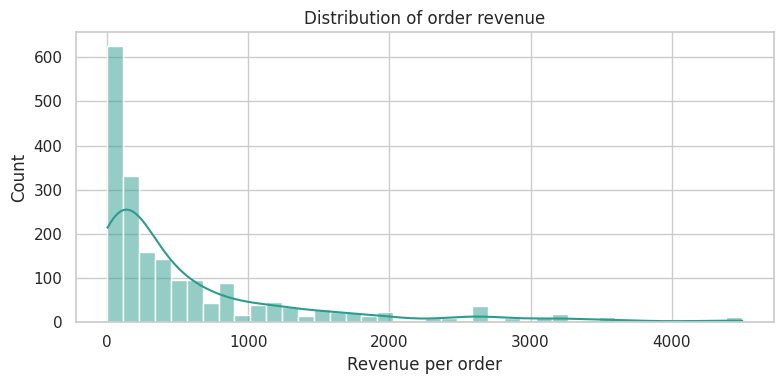

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["revenue"], bins=40, kde=True, color="#2a9d8f", ax=ax)
ax.set(title="Distribution of order revenue", xlabel="Revenue per order")
fig.tight_layout(); fig.savefig(OUT / "03_revenue_distribution.png", dpi=150); plt.show()

### Exercise 3.4 - Order value by payment method (box plot)

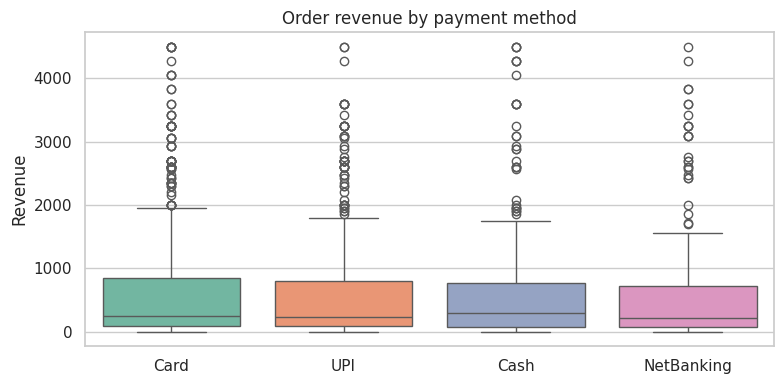

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="payment_method", y="revenue", hue="payment_method", palette="Set2", legend=False, ax=ax)
ax.set(title="Order revenue by payment method", xlabel="", ylabel="Revenue")
fig.tight_layout(); fig.savefig(OUT / "04_payment_boxplot.png", dpi=150); plt.show()

### Exercise 3.5 - Region x category heatmap

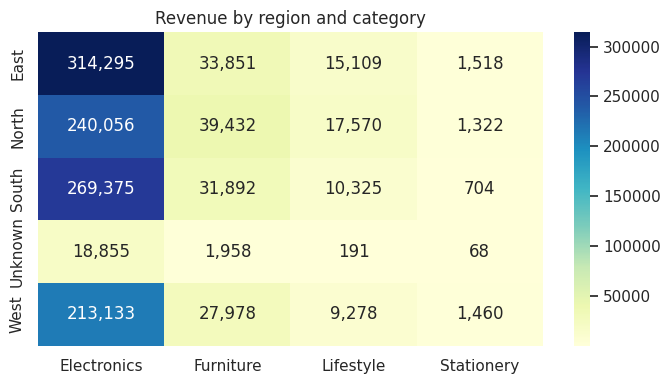

In [17]:
heat = df.pivot_table(index="region", columns="category", values="revenue", aggfunc="sum")
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(heat, annot=True, fmt=",.0f", cmap="YlGnBu", ax=ax)
ax.set(title="Revenue by region and category", xlabel="", ylabel="")
fig.tight_layout(); fig.savefig(OUT / "05_region_heatmap.png", dpi=150); plt.show()

### Exercise 3.6 - Multi-panel dashboard (subplots)

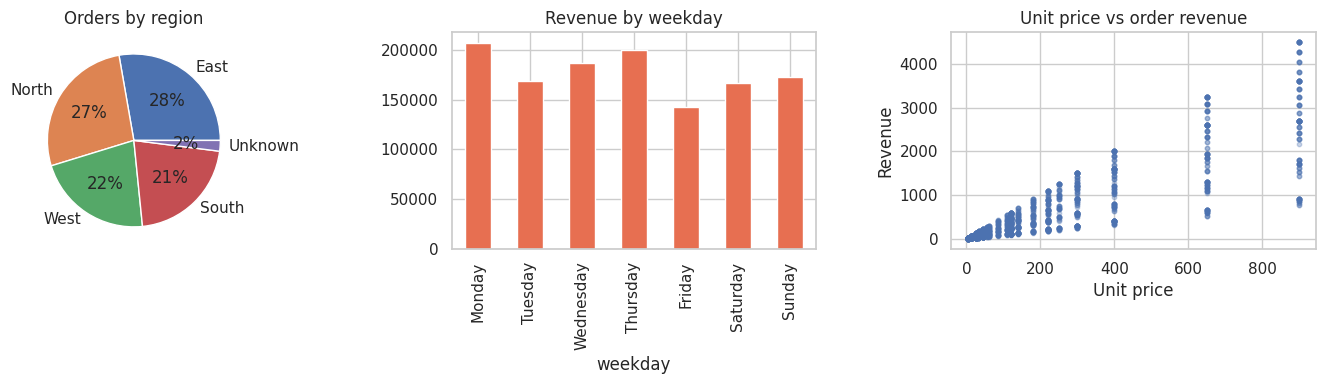

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
df["region"].value_counts().plot.pie(autopct="%1.0f%%", ax=axes[0], title="Orders by region", ylabel="")
df.groupby("weekday")["revenue"].sum().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
).plot.bar(ax=axes[1], color="#e76f51", title="Revenue by weekday")
axes[2].scatter(df["unit_price"], df["revenue"], alpha=.3, s=10)
axes[2].set(title="Unit price vs order revenue", xlabel="Unit price", ylabel="Revenue")
fig.tight_layout(); fig.savefig(OUT / "06_dashboard.png", dpi=150); plt.show()

## Part 4 - Basic analysis

### Exercise 4.1 - Descriptive statistics

In [19]:
df[["quantity", "unit_price", "discount_pct", "revenue"]].describe().T

,count,mean,std,min,25%,50%,75%,max
quantity,"2,000.00",2.96,1.42,1.00,2.00,3.00,4.00,5.00
unit_price,"2,000.00",217.21,251.35,4.00,35.00,120.00,300.00,900.00
discount_pct,"2,000.00",5.11,6.15,0.00,0.00,5.00,10.00,20.00
revenue,"2,000.00",624.18,862.28,3.20,90.00,240.00,794.00,"4,500.00"


### Exercise 4.2 - Correlation analysis

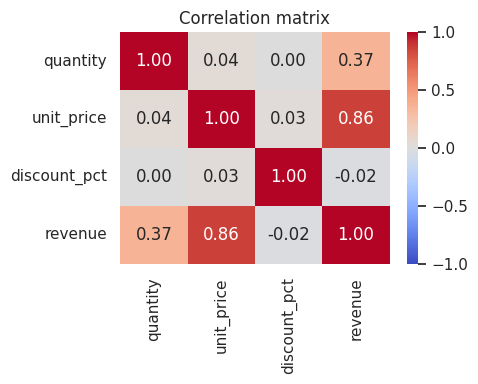

quantity        0.37
unit_price      0.86
discount_pct   -0.02
Name: revenue, dtype: float64

In [20]:
corr = df[["quantity", "unit_price", "discount_pct", "revenue"]].corr()
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix")
fig.tight_layout(); fig.savefig(OUT / "07_correlation.png", dpi=150); plt.show()
corr["revenue"].drop("revenue")

### Exercise 4.3 - Hypothesis test: does discounting change order quantity?

In [21]:
disc = df.loc[df.discount_pct > 0, "quantity"]
nodisc = df.loc[df.discount_pct == 0, "quantity"]
t, p = stats.ttest_ind(disc, nodisc, equal_var=False)
print(f"Mean quantity with discount   : {disc.mean():.3f}")
print(f"Mean quantity without discount: {nodisc.mean():.3f}")
print(f"Welch t-test: t = {t:.3f}, p = {p:.4f}")
print("Conclusion:", "significant difference" if p < 0.05 else "no significant difference at 5% level")

Mean quantity with discount   : 2.969
Mean quantity without discount: 2.961
Welch t-test: t = 0.134, p = 0.8931
Conclusion: no significant difference at 5% level


### Exercise 4.4 - Holiday-season effect (Nov-Dec vs rest of year)

In [22]:
df["holiday_season"] = df["order_date"].dt.month.isin([11, 12])
daily = df.groupby(["order_date", "holiday_season"])["revenue"].sum().reset_index()
season = daily.groupby("holiday_season")["revenue"].mean()
t2, p2 = stats.ttest_ind(daily.loc[daily.holiday_season, "revenue"],
                         daily.loc[~daily.holiday_season, "revenue"], equal_var=False)
print("Average daily revenue:"); print(season.rename({True: "Nov-Dec", False: "Jan-Oct"}))
print(f"\nUplift: {season[True] / season[False] - 1:.1%}   (Welch t = {t2:.2f}, p = {p2:.4g})")

Average daily revenue:
holiday_season
Jan-Oct   2,942.35
Nov-Dec   6,042.76
Name: revenue, dtype: float64

Uplift: 105.4%   (Welch t = 7.81, p = 3.058e-11)


### Exercise 4.5 - Simple linear regression: unit price vs average order revenue

slope = 2.951, intercept = -16.5, R^2 = 0.999, p = 1.36e-28


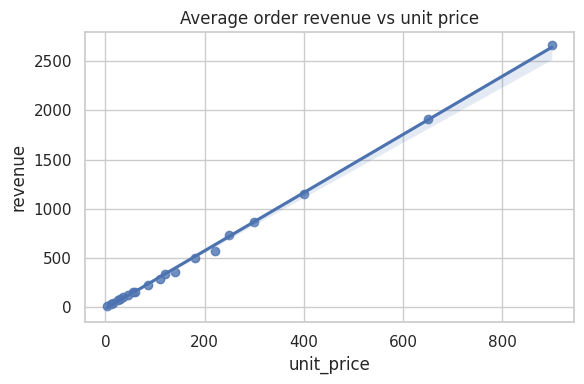

In [23]:
price_rev = df.groupby("unit_price")["revenue"].mean().reset_index()
res = stats.linregress(price_rev["unit_price"], price_rev["revenue"])
print(f"slope = {res.slope:.3f}, intercept = {res.intercept:.1f}, R^2 = {res.rvalue**2:.3f}, p = {res.pvalue:.2e}")
fig, ax = plt.subplots(figsize=(6, 4))
sns.regplot(data=price_rev, x="unit_price", y="revenue", ax=ax)
ax.set(title="Average order revenue vs unit price")
fig.tight_layout(); fig.savefig(OUT / "08_regression.png", dpi=150); plt.show()

### Exercise 4.6 - Customer segmentation (high / medium / low value)

In [24]:
customers["segment"] = pd.qcut(customers["total_spend"], 3, labels=["Low", "Medium", "High"])
seg = customers.groupby("segment", observed=True).agg(
    customers=("total_spend", "count"), avg_spend=("total_spend", "mean"), avg_orders=("orders", "mean"))
seg

,customers,avg_spend,avg_orders
segment,,,
Low,132,908.68,3.82
Medium,132,"2,704.53",5.14
High,132,"5,844.13",6.19


## Part 5 - Key findings
1. **Data quality:** the raw file had duplicate rows and missing values; after cleaning, every column is complete.
2. **Categories:** Electronics generates about 85% of total revenue (1.06M of 1.25M) because of its high unit prices.
3. **Seasonality:** average daily revenue in Nov-Dec is about 105% higher than Jan-Oct (p < 0.001).
4. **Price drives revenue:** unit price is the strongest correlate of order revenue (r = 0.86), quantity is moderate (r = 0.37), and discount level has almost none (r = -0.02). Discounts did not significantly change order quantity (p = 0.89).
5. **Customers:** the top third of customers (High segment) generates about 62% of total spend, so retention of these customers matters most.

*All exercises are reproducible: run the notebook top to bottom after `pip install -r requirements.txt`.*